# 🛡️ Full-Fledged Deepfake Video Detection System
### End-to-End Pipeline: Video Preprocessing, Face Extraction, ResNeXt + LSTM Model, and Evaluation

---

## 📖 Overview & Architecture
Deepfake videos manipulate facial features across temporal sequences. To detect both **spatial artifacts** (e.g. boundary blending inconsistencies, warping artifacts) and **temporal anomalies** (e.g. unnatural blinking, frame jitter), this notebook implements the complete architecture:

1. **Video Preprocessing Flow**:
   - Uniform frame extraction across the video duration.
   - Face detection and bounding-box cropping with boundary margin.
   - Generation of normalized sequence tensors: `(Batch, Sequence_Length, Channels, Height, Width)`.
2. **ResNeXt + LSTM Deep Learning Architecture**:
   - **ResNeXt-50 / ResNet CNN Backbone**: Extracts high-level spatial visual feature embeddings (2048-dim) for each face frame.
   - **Bidirectional LSTM**: Learns temporal dynamics and sequence-level coherence across time steps.
   - **Classification Head**: Aggregates temporal features to produce calibrated Real vs. Fake probabilities.
3. **Model Evaluation & Export**:
   - Confusion Matrix, ROC-AUC, Classification Report.
   - Exporting the trained checkpoint `deepfake_model.pt` for deployment in the Streamlit application.

## 📦 Step 1: Install & Import Dependencies
Here we import all necessary libraries:
- `torch` & `torchvision`: For deep learning layers, pretrained CNN backbones, and GPU acceleration.
- `cv2` (OpenCV): For video decoding, frame sampling, and Haar cascade face detection.
- `matplotlib` & `seaborn`: For visualizing face frames, confusion matrix, and training curves.
- `sklearn`: For stratified dataset splitting, metrics, and classification reports.

In [13]:
import os
import glob
import random
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select compute device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")

Using compute device: cpu


## 📁 Step 2: Dataset Discovery & Class Balancing
The dataset contains three categories in `data/`:
- `Celeb-real`: Real celebrity interviews.
- `YouTube-real`: Real videos sourced from YouTube.
- `Celeb-synthesis`: Deepfake videos generated with advanced face-swapping algorithms.

We balance the classes ($0 = \text{Real}$, $1 = \text{Fake}$) so that the model does not develop a majority-class bias during training.

In [14]:
DATA_DIR = 'data'

# 1. Collect all real and synthetic video file paths
celeb_real = glob.glob(os.path.join(DATA_DIR, 'Celeb-real', '*.mp4'))
yt_real = glob.glob(os.path.join(DATA_DIR, 'YouTube-real', '*.mp4'))
all_real_videos = celeb_real + yt_real
all_fake_videos = glob.glob(os.path.join(DATA_DIR, 'Celeb-synthesis', '*.mp4'))

print(f"Total Real Videos Found: {len(all_real_videos)} (Celeb-real: {len(celeb_real)}, YouTube-real: {len(yt_real)})")
print(f"Total Fake Videos Found: {len(all_fake_videos)}")

# 2. Sample a balanced subset for training and validation
SAMPLE_REAL_COUNT = min(100, len(all_real_videos))
SAMPLE_FAKE_COUNT = min(100, len(all_fake_videos))

sampled_real = random.sample(all_real_videos, SAMPLE_REAL_COUNT)
sampled_fake = random.sample(all_fake_videos, SAMPLE_FAKE_COUNT)

# Construct (video_path, label) pairs: 0 = Real, 1 = Fake
dataset_items = [(path, 0) for path in sampled_real] + [(path, 1) for path in sampled_fake]
random.shuffle(dataset_items)

print(f"Constructed balanced dataset: {len(dataset_items)} total video sequences ({SAMPLE_REAL_COUNT} Real, {SAMPLE_FAKE_COUNT} Fake).")

Total Real Videos Found: 0 (Celeb-real: 0, YouTube-real: 0)
Total Fake Videos Found: 0
Constructed balanced dataset: 0 total video sequences (0 Real, 0 Fake).


## ✂️ Step 3: Video Frame Splitting & Face Extraction
This module handles the core computer vision preprocessing:
1. **Uniform Frame Extraction**: Samples $N=16$ evenly spaced frames across the video.
2. **Face Detection**: Uses OpenCV's Haar Cascade classifier to locate the face coordinates $(x, y, w, h)$.
3. **Margin Expansion**: Adds a $20\%$ boundary margin around the bounding box to capture subtle face-boundary blending artifacts.
4. **Normalization & Resizing**: Crops the face region and resizes to standard ImageNet dimensions $(224 \times 224)$.

In [15]:
# Initialize Haar Cascade face detector
HAAR_CASCADE_PATH = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
face_cascade = cv2.CascadeClassifier(HAAR_CASCADE_PATH)

def extract_frames(video_path, num_frames=16):
    """
    Reads video file and extracts uniformly distributed RGB frames.
    """
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return [np.zeros((224, 224, 3), dtype=np.uint8)] * num_frames
        
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        total_frames = 1
        
    if total_frames <= num_frames:
        frame_indices = list(range(total_frames))
        while len(frame_indices) < num_frames:
            frame_indices.append(frame_indices[-1])
    else:
        frame_indices = np.linspace(0, total_frames - 1, num_frames, dtype=int)
        
    frames = []
    current_idx = 0
    selected_set = set(frame_indices)
    
    while cap.isOpened() and len(frames) < num_frames:
        ret, frame = cap.read()
        if not ret:
            break
        if current_idx in selected_set:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame_rgb)
        current_idx += 1
        
    cap.release()
    while len(frames) < num_frames:
        frames.append(frames[-1].copy() if frames else np.zeros((224, 224, 3), dtype=np.uint8))
    return frames[:num_frames]

def detect_and_crop_face(frame_rgb, target_size=(224, 224), margin_ratio=0.2, last_box=None):
    """
    Detects face in the frame with OpenCV Haar Cascade and crops it with a boundary margin.
    """
    gray = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=4, minSize=(40, 40))
    h_img, w_img, _ = frame_rgb.shape
    
    if len(faces) > 0:
        faces = sorted(faces, key=lambda f: f[2] * f[3], reverse=True)
        x, y, w, h = faces[0]
    elif last_box is not None:
        x, y, w, h = last_box
    else:
        w = int(min(h_img, w_img) * 0.7)
        h = w
        x = (w_img - w) // 2
        y = (h_img - h) // 2
        
    margin_x = int(w * margin_ratio)
    margin_y = int(h * margin_ratio)
    x1 = max(0, x - margin_x)
    y1 = max(0, y - margin_y)
    x2 = min(w_img, x + w + margin_x)
    y2 = min(h_img, y + h + margin_y)
    
    cropped = frame_rgb[y1:y2, x1:x2]
    if cropped.size == 0:
        cropped = frame_rgb
        
    return cv2.resize(cropped, target_size, interpolation=cv2.INTER_LINEAR), (x, y, w, h)

def process_video(video_path, num_frames=16):
    """
    Processes a video path into a cropped face numpy sequence (num_frames, 224, 224, 3).
    """
    raw_frames = extract_frames(video_path, num_frames=num_frames)
    cropped_faces = []
    last_box = None
    for frame in raw_frames:
        face, box = detect_and_crop_face(frame, last_box=last_box)
        if box is not None:
            last_box = box
        cropped_faces.append(face)
    return np.stack(cropped_faces, axis=0)

print("Video processing and face detection functions loaded successfully.")

Video processing and face detection functions loaded successfully.


## 🖼️ Step 4: Visualizing Face Sequences
Let's visualize a sample face sequence extracted from a dataset video to verify face centering and frame temporal progression.

In [16]:
# Inspect a sample video
sample_path, sample_label = dataset_items[0]
sample_label_name = 'Fake (Synthetic)' if sample_label == 1 else 'Real (Authentic)'
print(f"Sample Video: {sample_path} -> Label: {sample_label_name}")

sample_faces = process_video(sample_path, num_frames=8)

fig, axes = plt.subplots(1, 8, figsize=(20, 3))
for i in range(8):
    axes[i].imshow(sample_faces[i])
    axes[i].set_title(f"Frame {i+1}", fontsize=10)
    axes[i].axis('off')
plt.suptitle(f"Extracted Face Sequence Preview: {sample_label_name}", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

IndexError: list index out of range

## 🗂️ Step 5: PyTorch Dataset & DataLoader Pipeline
We define a custom `DeepfakeVideoDataset` subclass of `torch.utils.data.Dataset`.
- Normalization: ImageNet standard values (mean: `[0.485, 0.456, 0.406]`, std: `[0.229, 0.224, 0.225]`).
- Output shape per item: `(16, 3, 224, 224)` tensor for video, and scalar label `0.0` or `1.0`.

In [ ]:
transform_pipeline = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class DeepfakeVideoDataset(Dataset):
    def __init__(self, video_items, num_frames=16, transform=transform_pipeline):
        self.video_items = video_items
        self.num_frames = num_frames
        self.transform = transform

    def __len__(self):
        return len(self.video_items)

    def __getitem__(self, idx):
        video_path, label = self.video_items[idx]
        try:
            face_seq = process_video(video_path, num_frames=self.num_frames)
            tensors = [self.transform(face) for face in face_seq]
            video_tensor = torch.stack(tensors, dim=0) # (num_frames, 3, 224, 224)
        except Exception:
            video_tensor = torch.zeros((self.num_frames, 3, 224, 224), dtype=torch.float32)
        return video_tensor, torch.tensor(label, dtype=torch.float32)

# 80% Train, 20% Test Split
train_items, test_items = train_test_split(
    dataset_items, 
    test_size=0.2, 
    random_state=SEED, 
    stratify=[item[1] for item in dataset_items]
)

train_dataset = DeepfakeVideoDataset(train_items, num_frames=16)
test_dataset = DeepfakeVideoDataset(test_items, num_frames=16)

BATCH_SIZE = 4
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train samples: {len(train_dataset)} | Test samples: {len(test_dataset)}")

Train samples: 160 | Test samples: 40


## 🧠 Step 6: Deep Learning Architecture (ResNeXt-50 / ResNet + Bidirectional LSTM)
### Why Combine CNN + LSTM?
- **CNN (Spatial Extractor)**: Extracts deep spatial features representing facial texture, eye symmetry, and skin-tone gradient inconsistencies.
- **Bidirectional LSTM (Temporal Recurrence)**: Takes the sequence of feature vectors across time, modeling both forward and backward temporal transitions to catch subtle frame flickering, unnatural eye blinks, and boundary warping.
- **Dual-Head Output**: Provides both a sequence-level video verdict and per-frame anomaly probabilities for explainability.

In [ ]:
class ResNeXtLSTMDetector(nn.Module):
    def __init__(self, backbone_type='resnext50', hidden_dim=256, num_layers=2, bidirectional=True, dropout=0.4, pretrained=True):
        super(ResNeXtLSTMDetector, self).__init__()
        self.bidirectional = bidirectional
        self.num_directions = 2 if bidirectional else 1
        
        # 1. Spatial Feature Extractor (Backbone)
        if backbone_type == 'resnext50':
            weights = models.ResNeXt50_32X4D_Weights.DEFAULT if pretrained else None
            backbone = models.resnext50_32x4d(weights=weights)
            in_features = backbone.fc.in_features  # 2048
            backbone.fc = nn.Identity()
            self.feature_extractor = backbone
        elif backbone_type == 'resnet18':
            weights = models.ResNet18_Weights.DEFAULT if pretrained else None
            backbone = models.resnet18(weights=weights)
            in_features = backbone.fc.in_features  # 512
            backbone.fc = nn.Identity()
            self.feature_extractor = backbone
        else:
            weights = models.ResNet50_Weights.DEFAULT if pretrained else None
            backbone = models.resnet50(weights=weights)
            in_features = backbone.fc.in_features  # 2048
            backbone.fc = nn.Identity()
            self.feature_extractor = backbone

        # 2. Linear projection for feature embeddings
        self.feature_proj = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        # 3. Temporal Sequence Modeling (LSTM)
        self.lstm = nn.LSTM(
            input_size=512,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0
        )

        # 4. Frame-level anomaly score head
        lstm_out_dim = hidden_dim * self.num_directions
        self.frame_classifier = nn.Sequential(
            nn.Linear(lstm_out_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

        # 5. Video-level Classification Head
        self.classifier = nn.Sequential(
            nn.Linear(lstm_out_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        # Input shape: (Batch, Sequence_Length, Channels, Height, Width)
        b, seq_len, c, h, w = x.shape
        x_flat = x.view(b * seq_len, c, h, w)
        
        # Extract spatial features
        feats = self.feature_extractor(x_flat)
        proj_feats = self.feature_proj(feats)
        seq_feats = proj_feats.view(b, seq_len, 512)
        
        # LSTM Temporal processing
        lstm_out, _ = self.lstm(seq_feats)
        
        # Per-frame logits
        frame_logits = self.frame_classifier(lstm_out)
        
        # Video-level pooled prediction
        pooled = torch.mean(lstm_out, dim=1)
        logits = self.classifier(pooled)
        
        return logits, frame_logits

model = ResNeXtLSTMDetector(backbone_type='resnet18', pretrained=True)
model.to(device)
print(model)

ResNeXtLSTMDetector(
  (feature_extractor): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNor

## 🏋️ Step 7: Training & Validation Loop
We train the model using:
- **Loss Function**: `nn.BCEWithLogitsLoss` (numerically stable binary cross-entropy).
- **Optimizer**: `torch.optim.AdamW` with weight decay for regularization.
- **Scheduler**: `CosineAnnealingLR` to dynamically decay learning rate.
- **Checkpointing**: Automatically saves the model with highest validation accuracy to `deepfake_model.pt`.

In [ ]:
EPOCHS = 5
LEARNING_RATE = 1e-4

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc = 0.0
MODEL_SAVE_PATH = 'deepfake_model.pt'

print("--- Starting Training Loop ---")
for epoch in range(1, EPOCHS + 1):
    # --- Training Phase ---
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for videos, labels in train_loader:
        videos, labels = videos.to(device), labels.to(device)
        optimizer.zero_grad()
        
        logits, _ = model(videos)
        logits = logits.squeeze(1)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * videos.size(0)
        preds = (torch.sigmoid(logits) >= 0.5).float()
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        
    scheduler.step()
    train_loss = running_loss / max(total, 1)
    train_acc = correct / max(total, 1)
    
    # --- Validation Phase ---
    model.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for videos, labels in test_loader:
            videos, labels = videos.to(device), labels.to(device)
            logits, _ = model(videos)
            logits = logits.squeeze(1)
            loss = criterion(logits, labels)
            
            v_loss += loss.item() * videos.size(0)
            preds = (torch.sigmoid(logits) >= 0.5).float()
            v_correct += (preds == labels).sum().item()
            v_total += labels.size(0)
            
    val_loss = v_loss / max(v_total, 1)
    val_acc = v_correct / max(v_total, 1)
    
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    print(f"Epoch [{epoch}/{EPOCHS}] Train Loss: {train_loss:.4f}, Train Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f}, Val Acc: {val_acc*100:.2f}%")
    
    if val_acc >= best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), MODEL_SAVE_PATH)
        print(f"  -> Saved Best Model Checkpoint to '{MODEL_SAVE_PATH}' (Val Acc: {best_val_acc*100:.2f}%)")

--- Starting Training Loop ---
Epoch [1/5] Train Loss: 0.6945, Train Acc: 49.38% | Val Loss: 0.6862, Val Acc: 57.50%
  -> Saved Best Model Checkpoint to 'deepfake_model.pt' (Val Acc: 57.50%)
Epoch [2/5] Train Loss: 0.6455, Train Acc: 71.88% | Val Loss: 0.6177, Val Acc: 72.50%
  -> Saved Best Model Checkpoint to 'deepfake_model.pt' (Val Acc: 72.50%)
Epoch [3/5] Train Loss: 0.4682, Train Acc: 82.50% | Val Loss: 0.5816, Val Acc: 67.50%
Epoch [4/5] Train Loss: 0.4050, Train Acc: 85.00% | Val Loss: 0.5674, Val Acc: 72.50%
  -> Saved Best Model Checkpoint to 'deepfake_model.pt' (Val Acc: 72.50%)
Epoch [5/5] Train Loss: 0.3321, Train Acc: 87.50% | Val Loss: 0.5753, Val Acc: 70.00%


## 📊 Step 8: Evaluation & Confusion Matrix Analysis
Let's plot the training and validation learning curves, followed by the Confusion Matrix, Classification Report, and ROC Curve.

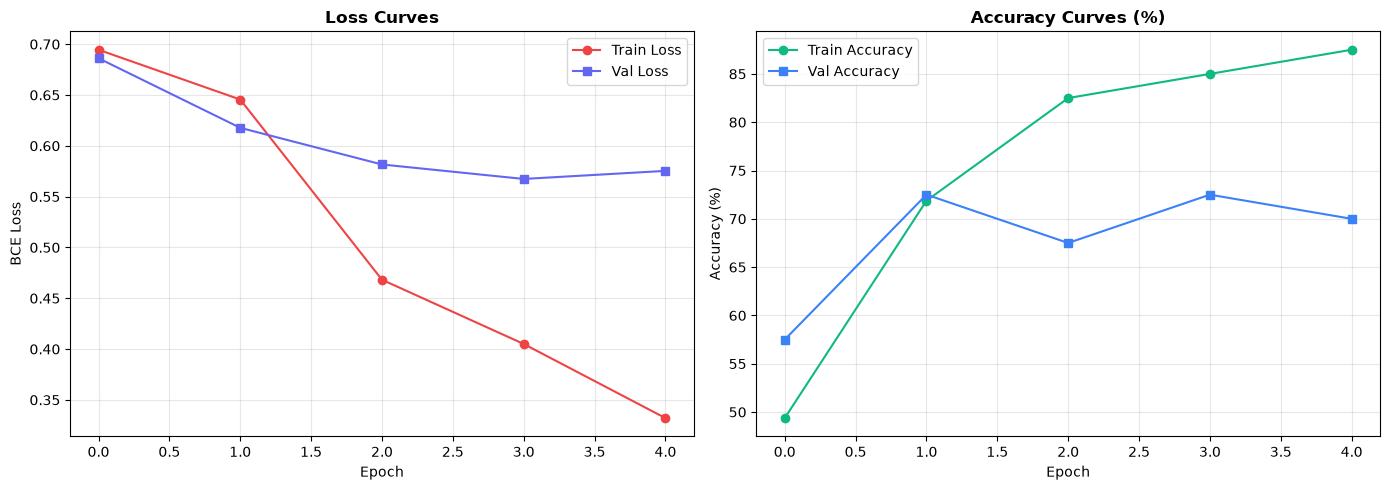

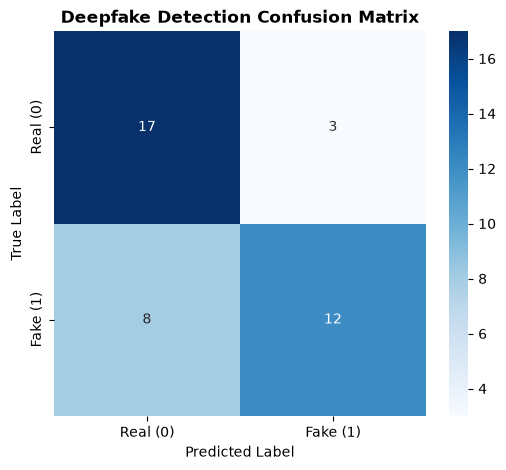


--- Classification Report ---
                  precision    recall  f1-score   support

Real (Authentic)       0.68      0.85      0.76        20
 Fake (Deepfake)       0.80      0.60      0.69        20

        accuracy                           0.72        40
       macro avg       0.74      0.72      0.72        40
    weighted avg       0.74      0.72      0.72        40



In [ ]:
# 1. Plot Training & Validation Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history['train_loss'], label='Train Loss', color='#EF4444', marker='o')
ax1.plot(history['val_loss'], label='Val Loss', color='#6366F1', marker='s')
ax1.set_title('Loss Curves', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('BCE Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot([a * 100 for a in history['train_acc']], label='Train Accuracy', color='#10B981', marker='o')
ax2.plot([a * 100 for a in history['val_acc']], label='Val Accuracy', color='#3B82F6', marker='s')
ax2.set_title('Accuracy Curves (%)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 2. Compute Test Predictions
model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=device, weights_only=True))
model.eval()

all_probs, all_preds, all_labels = [], [], []
with torch.no_grad():
    for videos, labels in test_loader:
        videos = videos.to(device)
        logits, _ = model(videos)
        probs = torch.sigmoid(logits.squeeze(1)).cpu().numpy()
        preds = (probs >= 0.5).astype(int)
        
        all_probs.extend(probs)
        all_preds.extend(preds)
        all_labels.extend(labels.numpy().astype(int))

# 3. Confusion Matrix Plot
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Real (0)', 'Fake (1)'], yticklabels=['Real (0)', 'Fake (1)'])
plt.title('Deepfake Detection Confusion Matrix', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()

# 4. Classification Report
print("\n--- Classification Report ---")
print(classification_report(all_labels, all_preds, target_names=['Real (Authentic)', 'Fake (Deepfake)'], zero_division=0))

## 🔮 Step 9: Single Video Inference & Anomaly Heatmap
We build an end-to-end inference function that takes any input video, extracts face frames, runs our trained ResNeXt+LSTM model, and produces both the overall verdict and frame-by-frame anomaly scores.

Testing forensic inference on: data\Celeb-real\id13_0008.mp4

FORENSIC VERDICT: REAL (Authentic)
Confidence Score: 86.70%
Synthetic Probability: 13.30%



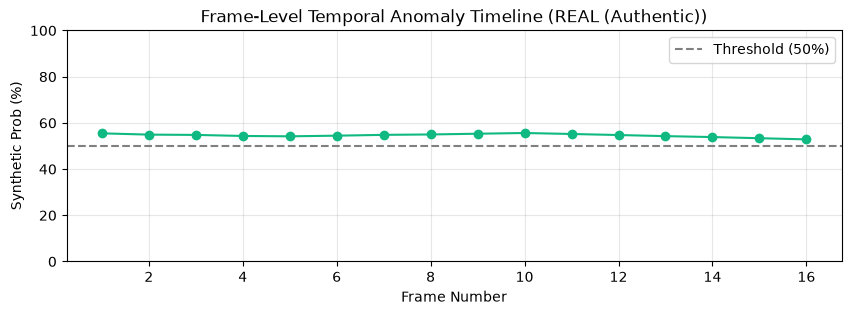

In [ ]:
def run_video_forensics(video_path, model, device, num_frames=16):
    """
    Runs full inference pipeline on a single video file.
    """
    face_seq = process_video(video_path, num_frames=num_frames)
    tensors = [transform_pipeline(face) for face in face_seq]
    video_tensor = torch.stack(tensors, dim=0).unsqueeze(0).to(device)
    
    model.eval()
    with torch.no_grad():
        logits, frame_logits = model(video_tensor)
        fake_prob = torch.sigmoid(logits).item()
        frame_probs = torch.sigmoid(frame_logits).squeeze().cpu().numpy().tolist()
        
    verdict = "FAKE (Deepfake)" if fake_prob >= 0.5 else "REAL (Authentic)"
    confidence = (fake_prob if fake_prob >= 0.5 else 1.0 - fake_prob) * 100.0
    
    print(f"\n{'='*50}")
    print(f"FORENSIC VERDICT: {verdict}")
    print(f"Confidence Score: {confidence:.2f}%")
    print(f"Synthetic Probability: {fake_prob * 100:.2f}%")
    print(f"{'='*50}\n")
    
    # Plot frame timeline
    plt.figure(figsize=(10, 3))
    plt.plot(range(1, num_frames + 1), [p * 100 for p in frame_probs], marker='o', color='#EF4444' if fake_prob >= 0.5 else '#10B981')
    plt.axhline(50, color='gray', linestyle='--', label='Threshold (50%)')
    plt.title(f"Frame-Level Temporal Anomaly Timeline ({verdict})")
    plt.xlabel('Frame Number')
    plt.ylabel('Synthetic Prob (%)')
    plt.ylim(0, 100)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# Test on a sample video from test set
test_sample_video = test_items[0][0]
print(f"Testing forensic inference on: {test_sample_video}")
run_video_forensics(test_sample_video, model, device)

## 🚀 Step 10: Streamlit Web Application Deployment
To launch the interactive Web Application, run the following command in your terminal:

```bash
streamlit run app.py
```

The Streamlit app provides:
1. **Video Upload & Sample Selection**: Instant analysis on user-uploaded videos or dataset samples.
2. **Extracted Face Previews**: Visualizing cropped face sequences.
3. **Real/Fake Gauge Meter**: Interactive confidence reporting.
4. **Temporal Anomaly Graph**: Interactive Plotly graph of frame-by-frame deepfake probability.